# 5. Predictive multiplicity

Notebook 04 compared 28 model configurations and found most of them statistically
indistinguishable on AUC. That is usually written up as a dead end: nothing beat the
baseline, so the baseline stands.

This notebook argues the opposite. **Aggregate equivalence is not individual
equivalence.** Two models with the same accuracy can flag different customers, and for the
customers they both flag, give different reasons. When that happens the choice between
them is not settled by any accuracy metric — it is a policy decision wearing technical
clothing.

That matters specifically in lending. Under a right to explanation the reasons given to a
declined customer are part of the decision. If an arbitrary modelling choice changes what
the customer is told, "the model said so" stops being a justification.

Three questions:

1. **Decisions.** What share of customers does one equally good model flag while another
   does not?
2. **Reasons.** For customers every model flags, do they all give the same top drivers?
3. **Who it affects.** Is the disagreement spread evenly, or concentrated in particular
   behavioural segments or demographic groups?

Two measures from the literature. **Ambiguity** is the share of customers receiving
conflicting decisions anywhere in the model set. **Discrepancy** is the largest share of
decisions that change between the deployed model and any single competitor.

Generated by `cd backend && python -m app.ml.multiplicity`.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
sys.path.insert(0, str(PROJECT_ROOT / "backend"))

RESULTS = PROJECT_ROOT / "backend" / "artifacts" / "multiplicity.json"
if not RESULTS.exists():
    raise FileNotFoundError(
        f"{RESULTS} not found. Generate it with:\n"
        "    cd backend && python -m app.ml.multiplicity"
    )

multiplicity = json.loads(RESULTS.read_text(encoding="utf-8"))

models = pd.Series(multiplicity["models"], name="test ROC-AUC").sort_values(ascending=False)
print(f"{len(models)} models, AUC spread {multiplicity['auc_spread']:.4f}")
print(f"matched flag rate: {multiplicity['matched_flag_rate']:.0%} of customers each\n")
models.to_frame()

6 models, AUC spread 0.0088
matched flag rate: 25% of customers each



,test ROC-AUC
LightGBM (deployed),0.7829
LightGBM (seed 777),0.7828
ExtraTrees,0.7817
XGBoost,0.7766
HistGradientBoosting,0.7758
RandomForest,0.7741


## The model set

Six configurations within **0.0088 AUC** of one another — well inside the ±0.01 split-to-split
noise measured in notebook 02. On any aggregate metric these are the same model. Two of
them are literally the same algorithm and hyperparameters differing only in random seed.

Every model is compared at a **matched flag rate**: each flags the same number of customers,
taken as its own top-k by score. Without that, differences in how models scale their
probabilities would masquerade as disagreement about individuals.

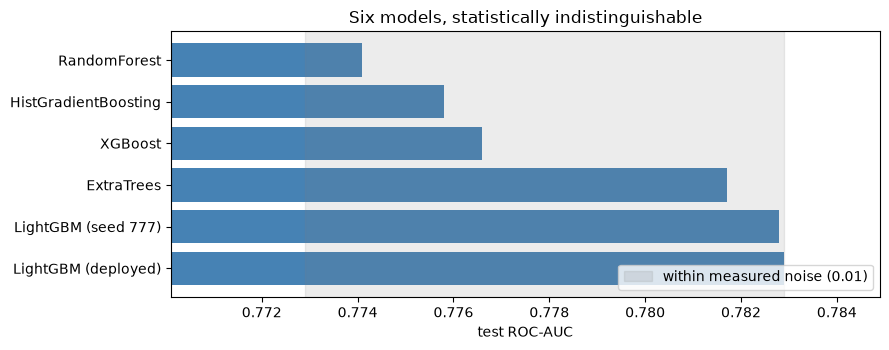

In [2]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(models.index, models.to_numpy(), color="steelblue")
ax.set_xlim(models.min() - 0.004, models.max() + 0.002)
ax.axvspan(models.max() - 0.01, models.max(), color="grey", alpha=0.15,
           label="within measured noise (0.01)")
ax.set_xlabel("test ROC-AUC")
ax.set_title("Six models, statistically indistinguishable")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 1. Decisions: who gets flagged

In [3]:
decisions = multiplicity["decisions"]
total = decisions["flagged_by_all"] + decisions["cleared_by_all"]
n_customers = round(total / (1 - decisions["ambiguity"]))

summary = pd.Series({
    "flagged by every model": decisions["flagged_by_all"],
    "cleared by every model": decisions["cleared_by_all"],
    "conflicting decisions": n_customers - total,
}, name="customers").to_frame()
summary["share"] = (summary["customers"] / n_customers).round(4)

print(f"AMBIGUITY   {decisions['ambiguity']:.1%} of customers receive conflicting decisions")
print(f"DISCREPANCY {decisions['discrepancy_vs_deployed']:.1%} of decisions change between")
print(f"            the deployed model and its closest competitor\n")
summary

AMBIGUITY   8.5% of customers receive conflicting decisions
DISCREPANCY 4.3% of decisions change between
            the deployed model and its closest competitor



,customers,share
flagged by every model,948,0.2107
cleared by every model,3168,0.7040
conflicting decisions,384,0.0853


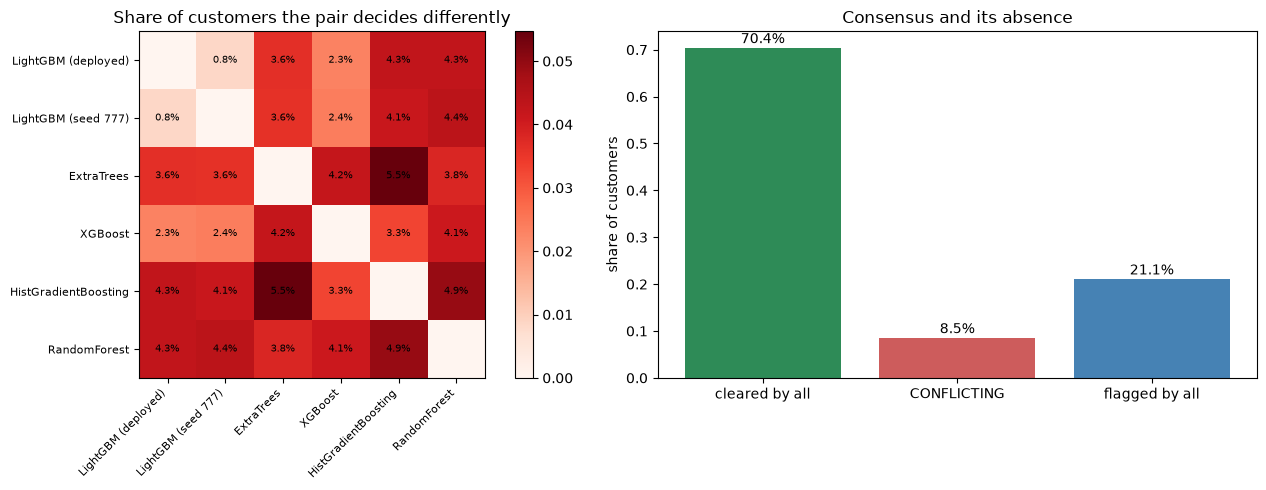

In [4]:
pairs = pd.DataFrame(decisions["pairwise_disagreement"])
names = list(models.index)
matrix = pd.DataFrame(0.0, index=names, columns=names)
for _, row in pairs.iterrows():
    matrix.loc[row["a"], row["b"]] = row["disagreement"]
    matrix.loc[row["b"], row["a"]] = row["disagreement"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

im = axes[0].imshow(matrix.to_numpy(), cmap="Reds", vmin=0)
axes[0].set_xticks(range(len(names)))
axes[0].set_xticklabels(names, rotation=45, ha="right", fontsize=8)
axes[0].set_yticks(range(len(names)))
axes[0].set_yticklabels(names, fontsize=8)
axes[0].set_title("Share of customers the pair decides differently")
for i in range(len(names)):
    for j in range(len(names)):
        if i != j:
            axes[0].text(j, i, f"{matrix.iloc[i, j]:.1%}", ha="center", va="center",
                         fontsize=7)
plt.colorbar(im, ax=axes[0])

shares = [decisions["cleared_by_all"] / n_customers,
          (n_customers - total) / n_customers,
          decisions["flagged_by_all"] / n_customers]
axes[1].bar(["cleared by all", "CONFLICTING", "flagged by all"], shares,
            color=["seagreen", "indianred", "steelblue"])
axes[1].set_ylabel("share of customers")
axes[1].set_title("Consensus and its absence")
for i, v in enumerate(shares):
    axes[1].text(i, v + 0.01, f"{v:.1%}", ha="center")

plt.tight_layout()
plt.show()

Roughly one customer in twelve has their outcome determined by which equally accurate model
happened to be chosen. Note that even two runs of the **same algorithm with the same
hyperparameters**, differing only in random seed, disagree about real people.

## 2. Reasons: what the customer is told

The decisions above at least mostly agree. This section restricts attention to customers
**every model flags** — maximum consensus, no ambiguity about the outcome — and asks
whether the models agree on *why*.

Drivers are computed by median substitution (occlusion) for all six models. That choice is
deliberate: using each model's own native explainer would confound disagreement **between
models** with disagreement **between explanation methods**, which notebook 06 measures
separately. One method, six models, so the only thing varying is the model.

In [5]:
reasons = multiplicity["reasons"]

pd.Series({
    "customers examined (flagged by all)": reasons["customers_examined"],
    "drivers compared per customer": reasons["top_k"],
    "received identical top-3 from all models": f"{reasons['identical_across_all_models']:.1%}",
    "models agreed on the single top driver": f"{reasons['top_driver_unanimous']:.1%}",
    "mean pairwise overlap (Jaccard)": f"{reasons['mean_pairwise_jaccard']:.3f}",
}, name="").to_frame()

,
customers examined (flagged by all),250
drivers compared per customer,3
received identical top-3 from all models,0.0%
models agreed on the single top driver,12.4%
mean pairwise overlap (Jaccard),0.492


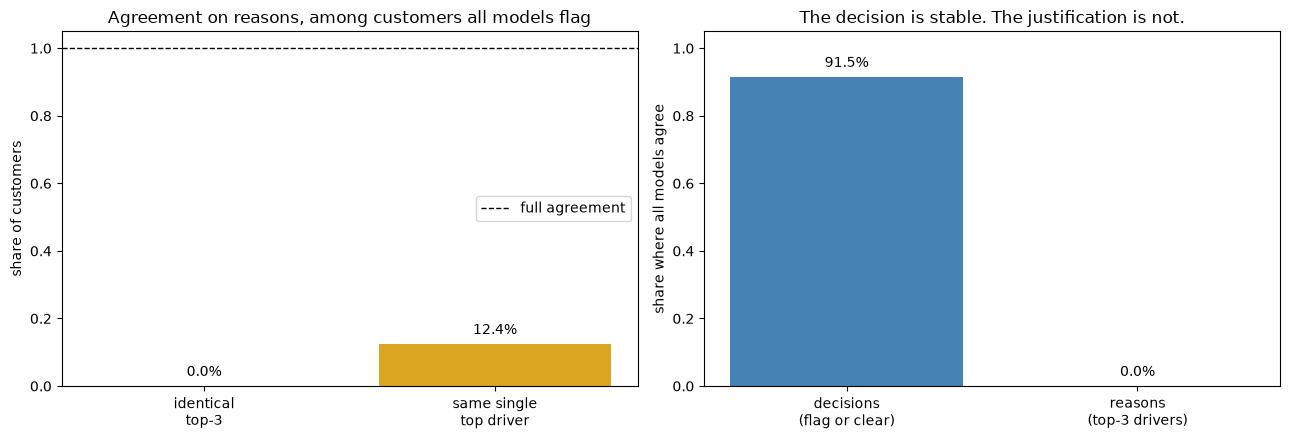

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(["identical\ntop-3", "same single\ntop driver"],
            [reasons["identical_across_all_models"], reasons["top_driver_unanimous"]],
            color=["indianred", "goldenrod"])
axes[0].axhline(1.0, color="black", ls="--", lw=1, label="full agreement")
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("share of customers")
axes[0].set_title("Agreement on reasons, among customers all models flag")
for i, v in enumerate([reasons["identical_across_all_models"],
                       reasons["top_driver_unanimous"]]):
    axes[0].text(i, v + 0.03, f"{v:.1%}", ha="center")
axes[0].legend()

axes[1].bar(["decisions\n(flag or clear)", "reasons\n(top-3 drivers)"],
            [1 - multiplicity["decisions"]["ambiguity"],
             reasons["identical_across_all_models"]],
            color=["steelblue", "indianred"])
axes[1].set_ylabel("share where all models agree")
axes[1].set_ylim(0, 1.05)
axes[1].set_title("The decision is stable. The justification is not.")
for i, v in enumerate([1 - multiplicity["decisions"]["ambiguity"],
                       reasons["identical_across_all_models"]]):
    axes[1].text(i, v + 0.03, f"{v:.1%}", ha="center")

plt.tight_layout()
plt.show()

### The result

**Not one customer in the sample received the same top three reasons from all six models**,
and in the large majority of cases the models do not agree even on the single most important
driver.

Set that against the decision panel. Models agree about the *outcome* for over 90% of
customers, and about the *explanation* for essentially none of them. A lender could run any
of these six, report the same accuracy, decline the same person, and tell them something
different about why.

That is the finding this project contributes. It is not that the models are bad — they are
equally good, which is exactly the problem.

## 3. Who it affects

If disagreement were spread evenly it would be a curiosity. The question is whether it
concentrates — and in particular whether it concentrates on people with the most at stake.

`lift_vs_overall` is a group's ambiguity rate divided by the overall rate. Above 1 means
members of that group are more exposed to arbitrary model choice than average.

In [7]:
concentration = {k: pd.DataFrame(v) for k, v in multiplicity["concentration"].items()}

for label, frame in concentration.items():
    print(f"\n=== by {label} ===")
    print(frame.to_string(index=False))


=== by segment ===
        group  customers  ambiguous_rate  lift_vs_overall  default_rate
   Distressed       1008          0.1677             1.96        0.4802
      Dormant        735          0.1374             1.61        0.2571
Moderate user       2757          0.0413             0.48        0.1172

=== by SEX ===
 group  customers  ambiguous_rate  lift_vs_overall  default_rate
  male       1766          0.0997             1.17        0.2537
female       2734          0.0761             0.89        0.2004

=== by EDUCATION ===
      group  customers  ambiguous_rate  lift_vs_overall  default_rate
high school        766          0.0940             1.10        0.2572
   graduate       1580          0.0899             1.05        0.2025
 university       2086          0.0810             0.95        0.2287
      other         68          0.0147             0.17        0.0294

=== by AGE ===
group  customers  ambiguous_rate  lift_vs_overall  default_rate
41-50        908          0.0

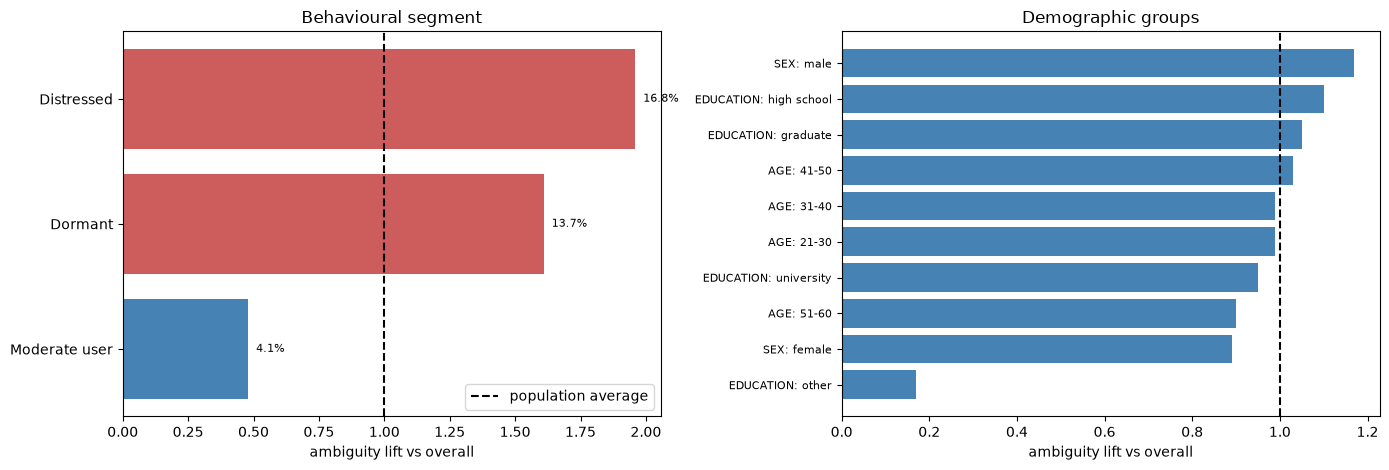

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

segments = concentration["segment"].sort_values("lift_vs_overall")
colours = ["indianred" if v > 1.25 else "steelblue" for v in segments["lift_vs_overall"]]
axes[0].barh(segments["group"], segments["lift_vs_overall"], color=colours)
axes[0].axvline(1.0, color="black", ls="--", label="population average")
axes[0].set_xlabel("ambiguity lift vs overall")
axes[0].set_title("Behavioural segment")
axes[0].legend()
for i, (_, r) in enumerate(segments.iterrows()):
    axes[0].text(r["lift_vs_overall"] + 0.03, i, f"{r['ambiguous_rate']:.1%}", va="center",
                 fontsize=8)

demographic = pd.concat([
    concentration[k].assign(attribute=k) for k in ("SEX", "EDUCATION", "AGE")
], ignore_index=True)
demographic["label"] = demographic["attribute"] + ": " + demographic["group"]
demographic = demographic.sort_values("lift_vs_overall")
axes[1].barh(demographic["label"], demographic["lift_vs_overall"], color="steelblue")
axes[1].axvline(1.0, color="black", ls="--")
axes[1].set_xlabel("ambiguity lift vs overall")
axes[1].set_title("Demographic groups")
axes[1].tick_params(axis="y", labelsize=8)

plt.tight_layout()
plt.show()

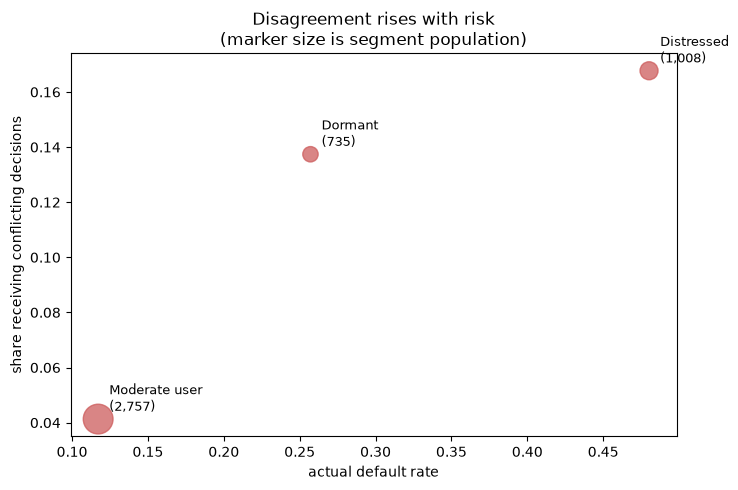

In [9]:
segments = concentration["segment"]
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(segments["default_rate"], segments["ambiguous_rate"],
           s=segments["customers"] / 6, color="indianred", alpha=0.75)
for _, r in segments.iterrows():
    ax.annotate(f"{r['group']}\n({r['customers']:,})",
                (r["default_rate"], r["ambiguous_rate"]),
                xytext=(8, 6), textcoords="offset points", fontsize=9)
ax.set_xlabel("actual default rate")
ax.set_ylabel("share receiving conflicting decisions")
ax.set_title("Disagreement rises with risk\n(marker size is segment population)")
plt.tight_layout()
plt.show()

### Read this carefully

**Disagreement concentrates in the highest-risk segment**, at roughly twice the population
rate. These are the customers most likely to be declined and least able to absorb an
arbitrary outcome. The final chart shows the relationship directly: the more risk a segment
carries, the less the models agree about its members.

**Demographic concentration is much weaker.** Sex, education and age all sit close to the
population average. This is a *behavioural* effect, not a demographic one — which makes it a
governance problem rather than a protected-attribute problem, and it would not be caught by
any of the fairness metrics in notebook 02. Disparate impact and equalized odds are computed
for a single model; neither can see that a different, equally valid model would have decided
otherwise.

## Limitations

**One explanation method.** Drivers come from occlusion for every model. That was necessary
to isolate model disagreement, but occlusion is known to disagree with SHAP and LIME on this
data, so "0% identical" is partly a property of its sensitivity. Repeating the comparison
with tree SHAP across the tree models would test how much of the effect survives.

**One split, one seed.** Ambiguity was measured on a single test split. The fairness
analysis in notebook 02 showed how badly single-split results can mislead, and the same
caution applies here.

**The flag rate is a choice.** Models are compared at 25%. A stricter or looser cut-off
would change the absolute numbers, though not the direction.

## Conclusion

Twenty-eight configurations were statistically indistinguishable, and notebook 04 presented
that as a ceiling. Seen individually it is something else: a set of equally defensible models
that disagree about 8.5% of customers, give different reasons to almost all of them, and
disagree most about the people with the most to lose.

The practical consequence is that selecting a model on validation AUC alone leaves a
material decision unmade. Where several candidates are equivalent on accuracy, stability of
decisions and of explanations is a legitimate tie-breaker — and it is measurable, as this
notebook shows.